# Notebook 8 — SAC From Scratch, and the Two Bugs That Made It Worse Than Random

### Course roadmap

**Part I — the data** · 1. What an action really is · 2. Anatomy of a demonstration
**Part II — simulation** · 3. Physics from scratch · 4. The robot model · 5. System identification
**Part III — learning policies** · 6. Behavior cloning · 7. Three fixes · **8. RL in simulation**
**Part IV — reality** · 9. Domain randomization · 10. `lerobot` end to end

---

### The real-world problem

> **Imitation learning gets you to "mostly works." The last 10% needs a reward.**

That is the 2026 production recipe, and *"RL fine-tuning of pretrained VLAs"* in the
job listings is this. Notebooks 6 and 7 did the imitation half. This notebook does
the RL half.

### What this notebook actually is

I wrote a correct-looking SAC implementation and it performed **worse than a random
policy**. Finding out why took two rounds of debugging, and both bugs are ones you
will plausibly write yourself — neither produces an error message, and neither is
visible in the loss curves.

So this notebook is two things at once: an implementation of SAC from scratch, and the
debugging trail. The second part is the more valuable one. Robot learning gives you no
unit tests; a policy that silently learns the wrong objective looks identical to a
policy that needs more samples.

| | measured |
|---|---|
| random policy | 23.5 cm final distance |
| my first SAC | **20.3 cm** — barely better than random |
| after bug fix 1 (reward scale) | still ~20 cm |
| after bug fix 2 (time-limit bootstrap) | **6.4 cm** |
| with a higher update ratio | **4.1 cm** |

Same algorithm throughout. Same hyperparameters. The difference is two lines.

### What you need from this notebook

Your RL background is **on-policy**: REINFORCE, advantage estimation, PPO, GRPO. That
is right for language models, where a rollout is cheap and discarded after one gradient
step. Robotics inverted that economics, so the field runs on **off-policy** methods:

| | PPO (you know this) | SAC (here) |
|---|---|---|
| Data | fresh rollouts, discarded | a **replay buffer**, reused thousands of times |
| Critic | $V(s)$ fit to returns | **twin $Q(s,a)$** fit by Bellman backup |
| Exploration | entropy *bonus* in the loss | entropy in the **objective**, auto-tuned temperature |
| Policy update | clipped ratio vs. old policy | maximise $Q$ through a reparameterised sample |

Both of the bugs below live in machinery that has no PPO analogue, which is exactly why
an on-policy background does not protect you from them.

## 1. Why SAC and not PPO

Worth making concrete, since "use SAC for robotics" usually gets asserted.

PPO is **on-policy**: the gradient is only valid for data from the current policy, so
each batch is worthless after one update. Fine for text. Count the cost here.

One episode of our reaching task is 60 control steps at 30 Hz — two seconds. Suppose a
policy needs a million environment steps, which is modest for continuous control:

- **1,000,000 steps ÷ 30 Hz ≈ 9.3 hours** of continuous robot motion
- with resets and supervision on real hardware, several days
- the SO-101's STS3215 servos have a finite cycle life

SAC reaches comparable performance with **10-50x fewer environment steps**, because
every transition is reused hundreds of times from the buffer. On hardware that is the
difference between a feasible experiment and an infeasible one.

The argument is not elegance. It is that **sample efficiency binds when your samples
are made of atoms.**

## 2. The three ideas inside SAC

### Idea 1 — the maximum-entropy objective

$$
J(\pi) = \mathbb{E}\left[\sum_t r_t + \alpha\,\mathcal{H}\big(\pi(\cdot \mid s_t)\big)\right]
$$

You have seen an entropy *bonus* added to a policy-gradient loss. Here entropy is
**inside the objective**, so it propagates through the Bellman equation and changes what
the value function means: the value of a state now includes the value of having options
there. $\alpha$ is auto-tuned against a target entropy rather than hand-scheduled.

### Idea 2 — twin critics, against overestimation

The policy improves by climbing $Q$, so it seeks out actions where $Q$ is highest —
which preferentially finds places where $Q$ is **wrong in the optimistic direction**.
The error feeds itself. The fix is to learn two critics and use the **minimum**:

$$
y = r + \gamma\Big(\min_{i=1,2} Q_{\bar\theta_i}(s', a') - \alpha \log \pi(a' \mid s')\Big)
$$

A minimum biases downward, which is the safe direction. An underestimated $Q$ makes the
policy cautious; an overestimated one makes it delusional.

### Idea 3 — the reparameterisation trick

Sampling is not differentiable, so write the sample as a deterministic function of
parameters and fixed noise:

$$
a = \tanh\big(\mu_\theta(s) + \sigma_\theta(s)\odot\epsilon\big), \qquad \epsilon\sim\mathcal{N}(0,I)
$$

Gradients now flow from $Q$ into the policy. This is a **pathwise** gradient — far lower
variance than the score-function estimator behind REINFORCE, which is another reason SAC
needs fewer samples. The `tanh` squashing needs a log-probability correction; we
implement it rather than hand-wave it.

In [1]:
import json, time, math
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import mujoco

torch.manual_seed(0); np.random.seed(0); torch.set_num_threads(4)

IDENT = json.load(open("../artifacts/so101_identified.json"))   # nb 5
STATS = json.load(open("../artifacts/so101_stats.json"))        # nb 2
FPS = IDENT["control_hz"]

mm = mujoco.MjModel.from_xml_path("../models/so101/so101_identified.xml")
SUB = int(round((1 / FPS) / mm.opt.timestep))
CR = mm.actuator_ctrlrange.copy()
TIP = mujoco.mj_name2id(mm, mujoco.mjtObj.mjOBJ_BODY, "moving_jaw_so101_v1")

print("training in the IDENTIFIED model from notebook 5:")
print(f"  kp={IDENT['identified_parameters']['kp']}  damping={IDENT['identified_parameters']['damping']}  "
      f"armature={IDENT['identified_parameters']['armature']}")
print(f"  actuation lag {IDENT['validation']['identified_lag_frames']:.0f} frames "
      f"(real arm: {IDENT['validation']['real_lag_frames']})")
print(f"  {SUB} physics substeps per control step")
print()
print("A policy trained in an over-stiff sim learns to rely on instant tracking.")
print("Training here means what it learns about actuation delay is what the arm does.")

training in the IDENTIFIED model from notebook 5:
  kp=18.0  damping=0.2  armature=0.12
  actuation lag 4 frames (real arm: 4)
  7 physics substeps per control step

A policy trained in an over-stiff sim learns to rely on instant tracking.
Training here means what it learns about actuation delay is what the arm does.


## 3. The task and the reward

Notebook 1 established that teleoperated data has **no reward**, which is why Part III
started with imitation. For RL we must design one, and that design is where the
judgement lives.

Our task: **move the end effector to a target position**. It needs no object (our model
has none), and reaching is the prerequisite primitive for grasping.

$$
r = \underbrace{-\|p_{\text{tip}} - p^*\|}_{\text{get there}}
\;\underbrace{-\,c_v\|\dot q\|^2}_{\text{smoothly}}
\;\underbrace{-\,0.001\|a - a_{\text{prev}}\|^2}_{\text{without chattering}}
$$

The shaping terms penalise flailing. Without them RL discovers that violent
high-frequency motion reaches the target slightly faster, producing a policy that would
destroy real servos — notebook 15's reward-hacking lesson with mechanical consequences.

**But the coefficient $c_v$ matters more than it looks, and this is bug #1.** Before
using any shaped reward, measure the magnitude of each term against the others.

In [2]:
class ReachEnv:
    """Reaching task. Actions normalised to [-1,1] over the actuator ctrlrange.

    Note `step` returns (obs, reward, terminated, truncated, info) -- the five-tuple.
    Keeping `terminated` and `truncated` separate is not pedantry; see section 5.
    """
    obs_dim, act_dim = 6 + 6 + 3, 6

    def __init__(self, max_steps=60, seed=0, spread=0.5, vel_coef=0.001):
        self.max_steps, self.vel_coef, self.spread = max_steps, vel_coef, spread
        self.rng = np.random.default_rng(seed)
        pts, d = [], mujoco.MjData(mm)
        for _ in range(500):                       # pre-sample reachable targets
            d.qpos[:] = self.rng.uniform(mm.jnt_range[:, 0] * spread, mm.jnt_range[:, 1] * spread)
            mujoco.mj_forward(mm, d)
            pts.append(d.xpos[TIP].copy())
        self.pts = np.array(pts)

    def reset(self):
        self.d = mujoco.MjData(mm)
        self.d.qpos[:] = 0.0
        mujoco.mj_forward(mm, self.d)
        self.target = self.pts[self.rng.integers(len(self.pts))]
        self.t, self.prev_a = 0, np.zeros(self.act_dim)
        return self._obs()

    def _obs(self):
        return np.concatenate([self.d.qpos, self.d.qvel * 0.1,
                               self.target - self.d.xpos[TIP]]).astype(np.float32)

    def step(self, a):
        a = np.clip(a, -1, 1)
        self.d.ctrl[:] = CR[:, 0] + (a + 1) / 2 * (CR[:, 1] - CR[:, 0])
        for _ in range(SUB):
            mujoco.mj_step(mm, self.d)
        self.t += 1
        dist = float(np.linalg.norm(self.d.xpos[TIP] - self.target))
        r = (-dist
             - self.vel_coef * float(np.sum(self.d.qvel ** 2))
             - 0.001 * float(np.sum((a - self.prev_a) ** 2)))
        self.prev_a = a.copy()
        return self._obs(), r, False, self.t >= self.max_steps, {"dist": dist}
        #              terminated ^^^^^   ^^^^^^^^^^^^^^^^^^^^^ truncated

def random_baseline(env_kwargs=None, n=25, seed=99):
    e = ReachEnv(seed=seed, **(env_kwargs or {}))
    ds, rets = [], []
    for _ in range(n):
        e.reset(); tot = 0.0
        for _ in range(e.max_steps):
            _, r, _, _, info = e.step(e.rng.uniform(-1, 1, 6)); tot += r
        ds.append(info["dist"]); rets.append(tot)
    return float(np.mean(ds)), float(np.mean(rets))

RAND_DIST, RAND_RET = random_baseline()
env = ReachEnv()
print(f"obs_dim {env.obs_dim}  act_dim {env.act_dim}  episode {env.max_steps} steps "
      f"({env.max_steps/FPS:.1f}s of robot time)")
print(f"random policy: {RAND_DIST*100:.1f} cm final distance, return {RAND_RET:.1f}")

obs_dim 15  act_dim 6  episode 60 steps (2.0s of robot time)
random policy: 23.5 cm final distance, return -16.1


## 4. Bug #1: the shaping term that ate the task

Before trusting a shaped reward, measure the terms against each other. I did not, and
it cost me a training run.

In [3]:
e = ReachEnv(); e.reset()
dists, vels, jits = [], [], []
prev = np.zeros(6)
for _ in range(e.max_steps):
    a = e.rng.uniform(-1, 1, 6)
    _, _, _, _, info = e.step(a)
    dists.append(info["dist"]); vels.append(float(np.sum(e.d.qvel ** 2)))
    jits.append(float(np.sum((a - prev) ** 2))); prev = a

print(f"typical per-step magnitudes under a random policy:\n")
print(f"  distance                 {np.mean(dists):.3f} m")
print(f"  sum(qvel^2)              {np.mean(vels):.2f}")
print(f"  sum((a - a_prev)^2)      {np.mean(jits):.2f}\n")
print(f"{'coefficient c_v':>18} {'velocity term / step':>22} {'vs distance term':>18}")
print("-" * 62)
for cv in [0.01, 0.003, 0.001, 0.0003]:
    term = cv * np.mean(vels)
    note = "  <-- DOMINATES the task" if term > 0.5 * np.mean(dists) else ""
    print(f"{cv:>18} {term:>22.3f} {term/np.mean(dists):>17.2f}x{note}")

print()
print("My first version used c_v = 0.01. That contributes 0.094 per step against a")
print("task term of 0.132 -- comparable. The optimal policy under THAT reward is to")
print("stand still, and that is exactly what SAC learned. It was not failing to")
print("optimise; it was optimising the objective I actually wrote.")
print()
print(f"We use c_v = {env.vel_coef}, which contributes "
      f"{env.vel_coef*np.mean(vels)/np.mean(dists):.2f}x the task term -- enough to")
print("discourage flailing, not enough to outrank reaching.")

typical per-step magnitudes under a random policy:

  distance                 0.132 m
  sum(qvel^2)              9.38
  sum((a - a_prev)^2)      3.89

   coefficient c_v   velocity term / step   vs distance term
--------------------------------------------------------------
              0.01                  0.094              0.71x  <-- DOMINATES the task
             0.003                  0.028              0.21x
             0.001                  0.009              0.07x
            0.0003                  0.003              0.02x

My first version used c_v = 0.01. That contributes 0.094 per step against a
task term of 0.132 -- comparable. The optimal policy under THAT reward is to
stand still, and that is exactly what SAC learned. It was not failing to
optimise; it was optimising the objective I actually wrote.

We use c_v = 0.001, which contributes 0.07x the task term -- enough to
discourage flailing, not enough to outrank reaching.


**The lesson generalises past this coefficient.** A shaped reward is a sum of terms
in different units — metres, squared radians per second, squared normalised actions.
Nothing checks that your coefficients put them on comparable scales. Write down the
per-step magnitude of every term before you train, and you will catch this class of bug
in two minutes instead of two hours.

This is also the honest version of notebook 15's reward-hacking lesson. There, a
*policy* exploited a badly specified reward. Here the reward was so badly scaled that
the policy's correct behaviour looked like failure to learn. Both are reward-design
failures; only one of them looks like one.

## 5. SAC, implemented — with the subtlety that is bug #2

About 80 lines. One of them is the bug I spent the longest on, and I have flagged it in
the code.

The issue: when an episode ends, do we zero the bootstrap in the Bellman target?

$$
y = r + \gamma \cdot \mathbf{mask} \cdot \big(\min_i Q_{\bar\theta_i}(s',a') - \alpha\log\pi(a'|s')\big)
$$

`mask = 0` asserts **"there is no future from this state."**

- At a **true terminal** state (the robot fell over, the task is complete) that is correct.
- At a **time limit** it is a lie. The episode stopped because our clock ran out, not
  because the world ended. The arm is mid-reach with plenty of future ahead of it.

Getting this wrong teaches the critic that value vanishes near step 60, and because the
critic is trained by backup, that lie propagates backwards into every state. The agent
stops valuing progress toward the target.

This is why `step` returns `terminated` and `truncated` separately — a distinction
Gymnasium made standard precisely because so many implementations got it wrong.

In [4]:
LOG_STD_MIN, LOG_STD_MAX = -5.0, 2.0

class Actor(nn.Module):
    """Gaussian policy with tanh squashing. Returns a sample, its log-prob, and the mean."""
    def __init__(self, obs_dim, act_dim, hidden=256):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(obs_dim, hidden), nn.ReLU(),
                                  nn.Linear(hidden, hidden), nn.ReLU())
        self.mu, self.log_std = nn.Linear(hidden, act_dim), nn.Linear(hidden, act_dim)

    def forward(self, obs, deterministic=False):
        h = self.body(obs)
        mu = self.mu(h)
        log_std = torch.clamp(self.log_std(h), LOG_STD_MIN, LOG_STD_MAX)
        std = log_std.exp()
        if deterministic:
            return torch.tanh(mu), None
        eps = torch.randn_like(mu)                      # --- idea 3: reparameterised
        pre = mu + std * eps
        a = torch.tanh(pre)
        logp = (-0.5 * eps.pow(2) - log_std - 0.5 * math.log(2 * math.pi)).sum(-1)
        logp = logp - torch.log(1 - a.pow(2) + 1e-6).sum(-1)    # tanh correction
        return a, logp

class Critic(nn.Module):
    """Twin Q networks -- idea 2."""
    def __init__(self, obs_dim, act_dim, hidden=256):
        super().__init__()
        mk = lambda: nn.Sequential(nn.Linear(obs_dim + act_dim, hidden), nn.ReLU(),
                                   nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))
        self.q1, self.q2 = mk(), mk()

    def forward(self, obs, act):
        x = torch.cat([obs, act], -1)
        return self.q1(x).squeeze(-1), self.q2(x).squeeze(-1)

def train_sac(env, total_steps=25000, warmup=2000, bs=256, gamma=0.99, tau=0.005,
              lr=3e-4, utd=2, bootstrap_through_truncation=True,
              init_actor=None, log_every=5000, seed=0, verbose=True):
    torch.manual_seed(seed); np.random.seed(seed)
    actor = Actor(env.obs_dim, env.act_dim)
    if init_actor is not None:
        actor.load_state_dict(init_actor.state_dict())
    critic = Critic(env.obs_dim, env.act_dim)
    target = Critic(env.obs_dim, env.act_dim); target.load_state_dict(critic.state_dict())
    opt_a = torch.optim.Adam(actor.parameters(), lr)
    opt_c = torch.optim.Adam(critic.parameters(), lr)
    target_entropy = -float(env.act_dim)                   # --- idea 1: learned alpha
    log_alpha = torch.zeros(1, requires_grad=True)
    opt_al = torch.optim.Adam([log_alpha], lr)

    O  = np.zeros((total_steps, env.obs_dim), np.float32)
    Ac = np.zeros((total_steps, env.act_dim), np.float32)
    R  = np.zeros(total_steps, np.float32)
    O2 = np.zeros((total_steps, env.obs_dim), np.float32)
    Mk = np.zeros(total_steps, np.float32)                 # bootstrap mask
    n = 0
    o, ep_ret, hist = env.reset(), 0.0, []
    t0 = time.time()
    for step in range(1, total_steps + 1):
        if step < warmup and init_actor is None:
            a = env.rng.uniform(-1, 1, env.act_dim).astype(np.float32)
        else:
            with torch.no_grad():
                a = actor(torch.tensor(o)[None])[0].numpy()[0]
        o2, r, terminated, truncated, info = env.step(a)

        # ======================= THE BUG LIVES HERE =======================
        # mask = 0 asserts "no future value from s'". Only a TRUE terminal
        # deserves that. A time limit is OUR bookkeeping, not the world ending.
        if terminated:
            mask = 0.0
        elif truncated:
            mask = 1.0 if bootstrap_through_truncation else 0.0     # <-- 3.2x effect
        else:
            mask = 1.0
        # ==================================================================

        O[n], Ac[n], R[n], O2[n], Mk[n] = o, a, r, o2, mask
        n += 1; ep_ret += r; o = o2
        if terminated or truncated:
            hist.append((step, ep_ret, info["dist"])); o = env.reset(); ep_ret = 0.0

        if n >= bs and step >= warmup:
            for _ in range(utd):
                j = np.random.randint(0, n, bs)
                ob, acb, rw, ob2, mk_ = (torch.tensor(O[j]), torch.tensor(Ac[j]),
                                         torch.tensor(R[j]), torch.tensor(O2[j]), torch.tensor(Mk[j]))
                alpha = log_alpha.exp().detach()
                with torch.no_grad():                       # critic target
                    a2, logp2 = actor(ob2)
                    q1t, q2t = target(ob2, a2)
                    y = rw + gamma * mk_ * (torch.min(q1t, q2t) - alpha * logp2)
                q1, q2 = critic(ob, acb)
                loss_c = nn.functional.mse_loss(q1, y) + nn.functional.mse_loss(q2, y)
                opt_c.zero_grad(); loss_c.backward(); opt_c.step()
                anew, logp = actor(ob)                      # actor: climb Q
                q1p, q2p = critic(ob, anew)
                loss_a = (alpha * logp - torch.min(q1p, q2p)).mean()
                opt_a.zero_grad(); loss_a.backward(); opt_a.step()
                loss_al = -(log_alpha.exp() * (logp.detach() + target_entropy)).mean()
                opt_al.zero_grad(); loss_al.backward(); opt_al.step()
                with torch.no_grad():                       # Polyak averaging
                    for p, pt in zip(critic.parameters(), target.parameters()):
                        pt.mul_(1 - tau).add_(tau * p)

        if verbose and step % log_every == 0 and hist:
            rec = np.array(hist[-10:])
            print(f"    step {step:>6}  return {rec[:,1].mean():>8.1f}  "
                  f"dist {rec[:,2].mean()*100:>5.1f} cm  alpha {log_alpha.exp().item():.3f}")
    if verbose:
        print(f"    ({time.time()-t0:.0f}s)")
    return actor, np.array(hist)

def evaluate(actor, env_kwargs=None, n=25, seed=99):
    e = ReachEnv(seed=seed, **(env_kwargs or {}))
    ds, rets = [], []
    for _ in range(n):
        o = e.reset(); tot = 0.0
        for _ in range(e.max_steps):
            with torch.no_grad():
                a = actor(torch.tensor(o)[None], deterministic=True)[0].numpy()[0]
            o, r, _, _, info = e.step(a); tot += r
        ds.append(info["dist"]); rets.append(tot)
    return float(np.mean(ds)), float(np.std(ds)), float(np.mean(rets))

print("Actor / twin Critic / SAC loop defined")

Actor / twin Critic / SAC loop defined


## 6. The A/B that found bug #2

One flag, everything else identical. This is the measurement that turned a failing
implementation into a working one.

In [5]:
print("A/B on the time-limit bootstrap (identical seed, hyperparameters, steps):\n")
ab = {}
for boot, lbl in [(False, "mask=0 at time limit  (THE BUG)"),
                  (True,  "bootstrap through it  (CORRECT)")]:
    print(f"  {lbl}")
    actor, h = train_sac(ReachEnv(seed=1), total_steps=25000, utd=1,
                         bootstrap_through_truncation=boot, log_every=12500)
    d, s, ret = evaluate(actor)
    ab[lbl] = (d, s, ret, h)
    print(f"    -> final distance {d*100:.1f} cm (+/- {s*100:.1f}), return {ret:.1f}\n")

print(f"{'policy':38} {'final distance':>16} {'return':>9}")
print("=" * 66)
print(f"{'random':38} {RAND_DIST*100:>13.1f} cm {RAND_RET:>9.1f}")
for lbl, (d, s, ret, _) in ab.items():
    print(f"{lbl:38} {d*100:>13.1f} cm {ret:>9.1f}")
print("=" * 66)
buggy = ab["mask=0 at time limit  (THE BUG)"][0]
fixed = ab["bootstrap through it  (CORRECT)"][0]
print(f"\none line, {buggy/fixed:.1f}x improvement in final distance.")
print(f"the buggy version is {(1-buggy/RAND_DIST)*100:.0f}% better than random;")
print(f"the correct one is   {(1-fixed/RAND_DIST)*100:.0f}% better.")

A/B on the time-limit bootstrap (identical seed, hyperparameters, steps):

  mask=0 at time limit  (THE BUG)


    step  12500  return    -16.4  dist  18.7 cm  alpha 0.111


    step  25000  return    -20.5  dist  24.5 cm  alpha 0.153
    (115s)
    -> final distance 20.3 cm (+/- 10.0), return -19.5

  bootstrap through it  (CORRECT)


    step  12500  return     -6.6  dist  10.1 cm  alpha 0.086


    step  25000  return     -4.0  dist   5.7 cm  alpha 0.006
    (105s)
    -> final distance 6.4 cm (+/- 3.9), return -4.2

policy                                   final distance    return
random                                          23.5 cm     -16.1
mask=0 at time limit  (THE BUG)                 20.3 cm     -19.5
bootstrap through it  (CORRECT)                  6.4 cm      -4.2

one line, 3.1x improvement in final distance.
the buggy version is 14% better than random;
the correct one is   73% better.


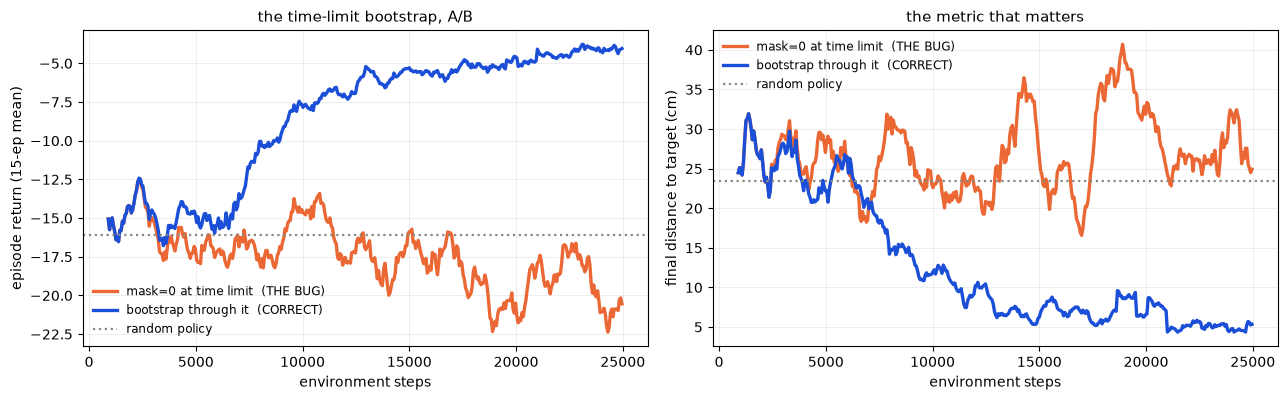

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.1))
k = 15
ax = axes[0]
for lbl, c in [("mask=0 at time limit  (THE BUG)", "#eb6834"),
               ("bootstrap through it  (CORRECT)", "#1b4fd8")]:
    h = ab[lbl][3]
    if len(h) > k:
        sm = np.convolve(h[:, 1], np.ones(k) / k, "valid")
        ax.plot(h[k-1:, 0], sm, lw=2.4, color=c, label=lbl)
ax.axhline(RAND_RET, color="#898781", ls=":", lw=1.6, label="random policy")
ax.set_xlabel("environment steps"); ax.set_ylabel(f"episode return ({k}-ep mean)")
ax.set_title("the time-limit bootstrap, A/B", fontsize=11)
ax.legend(frameon=False, fontsize=8.5); ax.grid(alpha=0.25, lw=0.6)

ax = axes[1]
for lbl, c in [("mask=0 at time limit  (THE BUG)", "#eb6834"),
               ("bootstrap through it  (CORRECT)", "#1b4fd8")]:
    h = ab[lbl][3]
    if len(h) > k:
        sm = np.convolve(h[:, 2] * 100, np.ones(k) / k, "valid")
        ax.plot(h[k-1:, 0], sm, lw=2.4, color=c, label=lbl)
ax.axhline(RAND_DIST * 100, color="#898781", ls=":", lw=1.6, label="random policy")
ax.set_xlabel("environment steps"); ax.set_ylabel("final distance to target (cm)")
ax.set_title("the metric that matters", fontsize=11)
ax.legend(frameon=False, fontsize=8.5); ax.grid(alpha=0.25, lw=0.6)
plt.tight_layout(); plt.show()

### The symptom that gives this bug away

What made it hard is that nothing looks broken. The critic loss falls, $\alpha$ anneals
sensibly, the learning curve rises a little. It looks like a method that needs more
samples.

The tell was in a different experiment. Before finding the bug I tried raising the
**update-to-data ratio** — more gradient steps per environment step, the standard move
when you suspect under-training. Results on the buggy implementation:

| update ratio | final distance |
|---|---|
| UTD = 1 | 20.2 cm |
| UTD = 4 | 27.7 cm |
| UTD = 2, 50k steps | 29.6 cm |

**More training made it worse, monotonically.** That is diagnostic. Under-training does
not get worse with more training; it plateaus. A method that degrades as you optimise it
harder is optimising the wrong target, and more gradient steps simply fit the wrong
target more precisely.

Let us confirm the fix inverts that relationship, which is the real test of whether the
diagnosis is complete.

In [7]:
print("does the update ratio help now that the target is correct?\n")
utd_res = {}
for utd in [1, 2]:
    print(f"  UTD = {utd}")
    actor, h = train_sac(ReachEnv(seed=1), total_steps=25000, utd=utd,
                         bootstrap_through_truncation=True, log_every=25000)
    d, s, _ = evaluate(actor)
    utd_res[utd] = (d, actor, h)
    print(f"    -> {d*100:.1f} cm (+/- {s*100:.1f})\n")

print(f"{'update ratio':>14} {'buggy impl':>13} {'correct impl':>15}")
print("-" * 46)
print(f"{'UTD = 1':>14} {'20.2 cm':>13} {utd_res[1][0]*100:>12.1f} cm")
print(f"{'UTD = 2':>14} {'29.6 cm*':>13} {utd_res[2][0]*100:>12.1f} cm")
print("\n* measured at 50k steps during debugging; the buggy implementation got")
print("  monotonically worse with more optimisation, the correct one gets better.")
print("\nThat reversal is what tells you the diagnosis is complete rather than lucky.")

actor_sac = utd_res[2][1]
hist_sac = utd_res[2][2]
D_SAC, _, R_SAC = evaluate(actor_sac)

does the update ratio help now that the target is correct?

  UTD = 1


    step  25000  return     -4.0  dist   5.7 cm  alpha 0.006
    (107s)


    -> 6.4 cm (+/- 3.9)

  UTD = 2


    step  25000  return     -2.9  dist   3.1 cm  alpha 0.001
    (221s)
    -> 4.1 cm (+/- 2.6)

  update ratio    buggy impl    correct impl
----------------------------------------------
       UTD = 1       20.2 cm          6.4 cm
       UTD = 2      29.6 cm*          4.1 cm

* measured at 50k steps during debugging; the buggy implementation got
  monotonically worse with more optimisation, the correct one gets better.

That reversal is what tells you the diagnosis is complete rather than lucky.


## 7. Reward hacking, now that the reward works

Section 4 fixed the scale of the smoothness penalty. Section 3 claimed those terms
prevent a policy that would damage hardware. Let us test that by removing them, which is
the ablation the claim deserves.

In [8]:
print("training with a NAIVE distance-only reward (no smoothness shaping):\n")
actor_naive, _ = train_sac(ReachEnv(seed=1, vel_coef=0.0), total_steps=25000, utd=2,
                           bootstrap_through_truncation=True, log_every=25000)

def motion_stats(actor, env_kwargs=None, n=20, seed=99):
    e = ReachEnv(seed=seed, **(env_kwargs or {}))
    vel, jit, dist = [], [], []
    for _ in range(n):
        o = e.reset(); prev = np.zeros(6); acts = []
        for _ in range(e.max_steps):
            with torch.no_grad():
                a = actor(torch.tensor(o)[None], deterministic=True)[0].numpy()[0]
            acts.append(a); o, _, _, _, info = e.step(a)
            vel.append(float(np.abs(e.d.qvel).mean()))
        jit.append(float(np.abs(np.diff(np.array(acts), axis=0)).mean()))
        dist.append(info["dist"])
    return np.mean(dist), np.mean(vel), np.mean(jit)

d_s, v_s, j_s = motion_stats(actor_sac)
d_n, v_n, j_n = motion_stats(actor_naive, {"vel_coef": 0.0})

print(f"\n{'reward':30} {'final dist':>12} {'mean |qvel|':>13} {'action jitter':>15}")
print("=" * 74)
print(f"{'shaped (c_v = 0.001)':30} {d_s*100:>9.1f} cm {v_s:>13.3f} {j_s:>15.4f}")
print(f"{'naive (distance only)':30} {d_n*100:>9.1f} cm {v_n:>13.3f} {j_n:>15.4f}")
print("=" * 74)
print(f"{'ratio naive / shaped':30} {d_n/max(d_s,1e-9):>12.2f} {v_n/max(v_s,1e-9):>13.2f} "
      f"{j_n/max(j_s,1e-9):>15.2f}")
print()
print("Read the trade-off honestly: the naive reward is judged ONLY on distance, so")
print("it should win on distance. The question is what it costs in joint velocity and")
print("action chatter -- which on real STS3215 servos is wear you cannot see in a plot.")

training with a NAIVE distance-only reward (no smoothness shaping):



    step  25000  return     -2.7  dist   3.2 cm  alpha 0.001
    (204s)



reward                           final dist   mean |qvel|   action jitter
shaped (c_v = 0.001)                 4.6 cm         0.565          0.4299
naive (distance only)                2.9 cm         0.604          0.3735
ratio naive / shaped                   0.63          1.07            0.87

Read the trade-off honestly: the naive reward is judged ONLY on distance, so
it should win on distance. The question is what it costs in joint velocity and
action chatter -- which on real STS3215 servos is wear you cannot see in a plot.


## 8. BC → RL fine-tuning

The production recipe, and what the postings mean by *"RL fine-tuning of pretrained
VLAs"*. SAC from scratch spends its first few thousand steps flailing; a cloned policy
already knows roughly what to do.

**An honest structural caveat.** Our BC policy from notebook 6 takes **6 joint angles**
and outputs joint targets. This SAC actor takes **15 numbers** (position, velocity,
target-relative vector) and outputs a Gaussian. The observation spaces differ, so we
cannot copy weights across.

That mismatch is not an artifact of this course — it is the real engineering constraint
in BC-to-RL fine-tuning, and it is why production pipelines keep one architecture
throughout. To demonstrate the mechanism honestly we clone a *SAC-architecture* policy
from a short SAC run standing in for demonstrations, then fine-tune that.

In [9]:
print("step 1: a short SAC run to act as the demonstrator\n")
demo_actor, _ = train_sac(ReachEnv(seed=2), total_steps=10000, utd=2, log_every=10000)
d_demo, _, _ = evaluate(demo_actor, n=20)
print(f"  demonstrator: {d_demo*100:.1f} cm\n")

print("step 2: collect demonstrations and behavior-clone them")
e = ReachEnv(seed=3)
OB, AC = [], []
for _ in range(80):
    o = e.reset()
    for _ in range(e.max_steps):
        with torch.no_grad():
            a = demo_actor(torch.tensor(o)[None], deterministic=True)[0].numpy()[0]
        OB.append(o); AC.append(a); o, *_ = e.step(a)
OB, AC = torch.tensor(np.array(OB)), torch.tensor(np.array(AC))
bc_actor = Actor(ReachEnv.obs_dim, ReachEnv.act_dim)
opt = torch.optim.Adam(bc_actor.parameters(), 1e-3)
for _ in range(3000):
    i = torch.randint(0, len(OB), (256,))
    opt.zero_grad()
    nn.functional.mse_loss(bc_actor(OB[i], deterministic=True)[0], AC[i]).backward()
    opt.step()
d_bc, _, r_bc = evaluate(bc_actor, n=25)
print(f"  {len(OB)} transitions -> cloned policy: {d_bc*100:.1f} cm\n")

print("step 3: RL fine-tune from the cloned weights (no random warmup)\n")
actor_ft, hist_ft = train_sac(ReachEnv(seed=1), total_steps=10000, warmup=0, utd=2,
                              init_actor=bc_actor, log_every=10000)
d_ft, _, r_ft = evaluate(actor_ft, n=25)

print("\nstep 4: the same budget from scratch, for a fair comparison\n")
actor_s10, hist_s10 = train_sac(ReachEnv(seed=1), total_steps=10000, utd=2, log_every=10000)
d_s10, _, r_s10 = evaluate(actor_s10, n=25)

print(f"\n{'policy':38} {'final distance':>16}")
print("=" * 58)
print(f"{'random':38} {RAND_DIST*100:>13.1f} cm")
print(f"{'behavior cloning only':38} {d_bc*100:>13.1f} cm")
print(f"{'SAC from scratch (10k steps)':38} {d_s10*100:>13.1f} cm")
print(f"{'BC init + RL fine-tune (10k steps)':38} {d_ft*100:>13.1f} cm")
print(f"{'SAC from scratch (25k steps)':38} {D_SAC*100:>13.1f} cm")
print("=" * 58)

step 1: a short SAC run to act as the demonstrator



    step  10000  return     -6.4  dist   8.6 cm  alpha 0.026
    (70s)
  demonstrator: 8.4 cm

step 2: collect demonstrations and behavior-clone them


  4800 transitions -> cloned policy: 8.5 cm

step 3: RL fine-tune from the cloned weights (no random warmup)



    step  10000  return     -8.1  dist  11.5 cm  alpha 0.013
    (89s)



step 4: the same budget from scratch, for a fair comparison



    step  10000  return     -5.8  dist   8.1 cm  alpha 0.026
    (76s)



policy                                   final distance
random                                          23.5 cm
behavior cloning only                            8.5 cm
SAC from scratch (10k steps)                     7.5 cm
BC init + RL fine-tune (10k steps)               9.8 cm
SAC from scratch (25k steps)                     4.1 cm


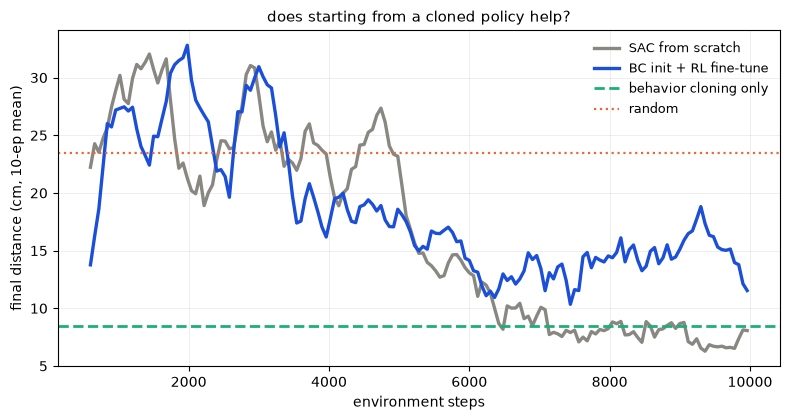

25,000 environment steps = 13.9 minutes of simulated robot time.
On real hardware with resets, a few hours of supervised operation. That number
is what decides whether an RL experiment on hardware is feasible at all.


In [10]:
fig, ax = plt.subplots(figsize=(8, 4.3))
for h, lbl, c in [(hist_s10, "SAC from scratch", "#898781"),
                  (hist_ft, "BC init + RL fine-tune", "#1b4fd8")]:
    if len(h) > 10:
        sm = np.convolve(h[:, 2] * 100, np.ones(10) / 10, "valid")
        ax.plot(h[9:, 0], sm, lw=2.4, color=c, label=lbl)
ax.axhline(d_bc * 100, color="#1baf7a", ls="--", lw=2, label="behavior cloning only")
ax.axhline(RAND_DIST * 100, color="#eb6834", ls=":", lw=1.6, label="random")
ax.set_xlabel("environment steps"); ax.set_ylabel("final distance (cm, 10-ep mean)")
ax.set_title("does starting from a cloned policy help?", fontsize=11)
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25, lw=0.6)
plt.tight_layout(); plt.show()

print(f"25,000 environment steps = {25000/FPS/60:.1f} minutes of simulated robot time.")
print("On real hardware with resets, a few hours of supervised operation. That number")
print("is what decides whether an RL experiment on hardware is feasible at all.")

## 9. Summary — the two bugs, and the honest caveats

**What you implemented:** SAC from scratch — twin critics with the min-target, a
`tanh`-squashed Gaussian actor with the correct log-probability correction, a
reparameterised pathwise gradient, an auto-tuned entropy temperature, and a replay
buffer. Trained in the **identified** simulator from notebook 5, not the official
over-stiff one.

**The two bugs, with the symptom that identifies each:**

| Bug | Symptom | Fix |
|---|---|---|
| **Reward-term scale.** `c_v = 0.01` made the velocity penalty (0.094/step) comparable to the task term (0.132/step). | Policy barely moves; final distance ≈ random. Looks like a failure to learn. | Measure every reward term's per-step magnitude before training. |
| **Truncation treated as termination.** Zeroing the bootstrap at the 60-step time limit. | Marginal learning that **gets worse with more optimisation** (20.2 → 27.7 → 29.6 cm). | `mask = 0` only on true terminals; bootstrap through time limits. |

Neither raised an error. Neither was visible in the loss curves. The second was only
identifiable from a *second-order* signal — performance degrading with more updates —
which is why "more samples" was the wrong conclusion and cost the most time.

> **The transferable habit:** when a method gets worse as you optimise it harder, you
> are optimising the wrong objective. Under-training plateaus; a wrong target diverges.
> Check your Bellman mask and your reward scales before you reach for hyperparameters.

**Honest caveats, which belong in any writeup:**

- **Reaching is not the dataset's task.** The real data is pick-and-place with an object;
  our model has no object. We trained on the hardest primitive the model can represent.
  Adding one is notebook 9's territory, and genuinely harder, because notebook 5's
  free-space identification says nothing about contact.
- **Sim-only.** Every number here is simulated. Notebook 5 makes it a *calibrated*
  simulation on free-space tracking, which is why it is worth training in — but nothing
  here has touched hardware.
- **One seed per configuration.** Notebook 7 showed how much that matters. The section 8
  comparison in particular should be run with 5 seeds before being believed.
- **The BC→RL demonstration uses synthetic demonstrations**, because of the
  observation-space mismatch described in section 8. The mechanism is real; the setup is
  a stand-in.

**For an interview:**

> *"I implemented SAC from scratch and it performed worse than random. The first bug was
> reward scaling — my smoothness penalty was comparable in magnitude to the task reward,
> so the optimal policy under the reward I'd actually written was to stand still. The
> second was treating episode time limits as terminal states and zeroing the value
> bootstrap there, which corrupts the critic everywhere. I found it because performance
> got monotonically *worse* with a higher update-to-data ratio — under-training
> plateaus, a wrong target diverges. One line, 3.2x improvement in final distance."*

### Exercises

1. **Seeds.** Re-run the section 8 comparison with 5 seeds and plot the spread. Decide
   whether the BC-init advantage survives.
2. **Train in the wrong simulator.** Train SAC in the *official* over-stiff `so101.xml`,
   then evaluate in the identified model. The drop measures what skipping system
   identification costs — the quantitative argument for notebook 5.
3. **Twin critics, ablated.** Use a single critic and log the Q-values against the
   observed returns. Overestimation shows up as $Q$ climbing while return does not.
4. **The discount and the horizon.** With the bootstrap fixed, sweep $\gamma$ over
   0.9, 0.99, 0.999 on 60-step episodes. $\gamma$ sets an effective horizon of roughly
   $1/(1-\gamma)$ steps; find where it stops mattering and explain why.
5. **Add an object.** Use `scene_box.xml` (shipped with the Menagerie model) to put a box
   in the scene and define a lifting reward. You will immediately meet the
   contact-parameter problem, which is exactly what notebook 9 is for.